# Cost, delay and paired uncertainty

How sensitive is the relative conclusion to implementation assumptions?

This notebook reviews saved retrospective evidence. New descriptive calculations are post-study analysis, not new strategy selection or an untouched test.

In [1]:
from pathlib import Path
import json,sys,math,statistics
r=Path.cwd()
if not (r/'artifacts/research').exists(): r=r.parent
sys.path.insert(0,str(r/'src'));sys.path.insert(0,str(r))
from scripts.review_visuals import table,figure,lines,bars
if 'display_bundle' not in globals():
 from IPython.display import display
 def display_bundle(data): display(data,raw=True)
b=json.loads((r/'artifacts/research/public_bundle.json').read_text());a=b['analysis']
p=json.loads((r/'artifacts/review/polish.json').read_text());chosen=b['selected']
print('Saved test:',b['as_of'],'Selected:',chosen,'Post-study review:',p['review_date'])

Saved test: 2025-12-31 Selected: stumps_24 Post-study review: 2026-11-25


## Archived cost reruns

Cost multipliers scale commissions and adverse slippage. Quantities can change through cash constraints.

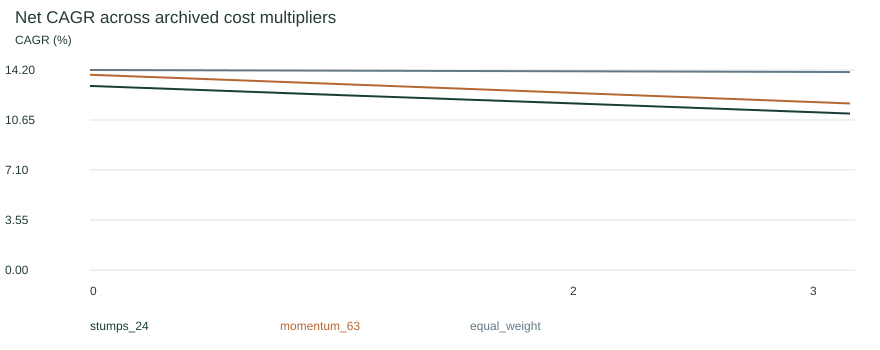

In [2]:
display_bundle(figure(lines('Net CAGR across archived cost multipliers',[0,1,2,3],{n:[100*b['stress'][n+'__cost'+str(k)]['cagr'] for k in range(4)] for n in [chosen,'momentum_63','equal_weight']},'CAGR (%)')))

## Execution delay reversal

The delayed outcome is a predeclared sensitivity, not a newly selected strategy.

In [3]:
display_bundle(table(['Policy','Primary CAGR','Extra-session-delay CAGR'],[[n,f'{b["results"][n]["metrics"]["cagr"]:.2%}',f'{b["stress"][n+"__delay1"]["cagr"]:.2%}'] for n in [chosen,'momentum_63','equal_weight']]))

Policy,Primary CAGR,Extra-session-delay CAGR
stumps_24,12.41%,15.83%
momentum_63,13.19%,11.54%
equal_weight,14.16%,14.47%


## Recompute the paired statistic

Preserve the paired calendar months and the declared block/repetition/seed settings.

In [4]:
from equity_research.statistics import block_bootstrap_difference
u=block_bootstrap_difference(b['results'][chosen]['monthly'],b['results']['momentum_63']['monthly'],block=b['config']['bootstrap_block_months'],reps=b['config']['bootstrap_repetitions'],seed=b['config']['seed']);assert u==b['uncertainty'];display_bundle(table(['Statistic','Value'],list(u.items())))

Statistic,Value
paired_months,36
mean_monthly_net_difference,-0.00031472322707744153
ci95_low,-0.009998581995489303
ci95_high,0.009885648664416588
block_months,3
repetitions,2000
seed,20261124
interpretation,"Circular time-block bootstrap interval for arithmetic mean paired monthly return difference; descriptive small-sample uncertainty, not proof of alpha."


## Interpretation

The interval contains zero. It is a descriptive interval for mean monthly differences, not an equivalence test, CAGR interval, PBO estimate or future win probability. Execution timing materially changes rankings.